# Replicating network analyses done by Baker et al 2022 on updated FlyWire Connectome data

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats
import sys

### Compiling data

In [3]:
connections = pd.read_csv('connections_princeton.csv.gz', compression='gzip').drop(columns='neuropil')
connections

,pre_root_id,post_root_id,syn_count,nt_type
0,720575940625363947,720575940623224444,12,GABA
1,720575940630432382,720575940618518557,67,ACH
2,720575940627314521,720575940626337738,10,GABA
3,720575940620280405,720575940620204726,15,ACH
4,720575940636942447,720575940613789411,1,GLUT
...,...,...,...,...
5342441,720575940610739918,720575940617129885,5,ACH
5342442,720575940653332385,720575940623905719,2,ACH
5342443,720575940622485887,720575940631031803,9,ACH
5342444,720575940620020534,720575940636489140,2,ACH


In [4]:
#group by nts so no repeated neuron connections appear

grouped_bynt = connections.groupby(['pre_root_id', 'post_root_id', 'nt_type'], as_index=False)[['syn_count']].sum()
grouped_bynt

,pre_root_id,post_root_id,nt_type,syn_count
0,720575940596125868,720575940605825666,ACH,6
1,720575940596125868,720575940608552405,ACH,6
2,720575940596125868,720575940609975854,ACH,5
3,720575940596125868,720575940613059993,ACH,9
4,720575940596125868,720575940613599129,ACH,6
...,...,...,...,...
3732455,720575940661339777,720575940622727152,ACH,37
3732456,720575940661339777,720575940625109995,ACH,5
3732457,720575940661339777,720575940627311491,ACH,40
3732458,720575940661339777,720575940628084873,ACH,19


In [5]:
#keep only strongest connection for duplicate connection with different nt types
grouped_bynt = grouped_bynt.sort_values(by = 'syn_count', ascending=False).drop_duplicates(subset=['pre_root_id', 'post_root_id'], keep='first')
grouped_bynt

,pre_root_id,post_root_id,nt_type,syn_count
3687238,720575940650935673,720575940640736371,GABA,2633
2320879,720575940628069501,720575940633305681,GABA,2597
3596036,720575940644702112,720575940625952755,GABA,2238
1631524,720575940623475324,720575940627497244,GABA,2179
1246516,720575940620975696,720575940624547622,DA,1872
...,...,...,...,...
3073466,720575940633914413,720575940615905130,GLUT,5
1582223,720575940623166600,720575940622950424,ACH,5
3073469,720575940633914413,720575940622525168,GLUT,5
1582220,720575940623166600,720575940618583877,ACH,5


In [6]:
#add celltypes

celltypes = pd.read_csv('consolidated_cell_types.csv.gz', compression='gzip')
celltypes

,root_id,primary_type,additional_type(s)
0,720575940596125868,T5c,NaN
1,720575940597856265,Tm16,NaN
2,720575940597944841,Tm7,CB3851
3,720575940598267657,TmY15,NaN
4,720575940599333574,Tm1,NaN
...,...,...,...
137672,720575940661335681,CB0180,NaN
137673,720575940661336193,TmY3,NaN
137674,720575940661337217,KCab-p,NaN
137675,720575940661338497,CB0904,NaN


In [7]:
#merge connections with cell type

firstmerge = grouped_bynt.merge(
    celltypes,
    how ='left',
    left_on = "pre_root_id",
    right_on = 'root_id'
).drop(columns=['root_id', 'additional_type(s)']).rename(columns={'primary_type':'type_pre'})

conns = firstmerge.merge(
    celltypes,
    how='left',
    left_on = 'post_root_id',
    right_on = 'root_id'
).drop(columns=['root_id', 'additional_type(s)']).rename(columns={'primary_type':'type_post'})

conns

,pre_root_id,post_root_id,nt_type,syn_count,type_pre,type_post
0,720575940650935673,720575940640736371,GABA,2633,Li32,Li30
1,720575940628069501,720575940633305681,GABA,2597,Li32,Li30
2,720575940644702112,720575940625952755,GABA,2238,LT39,Li33
3,720575940623475324,720575940627497244,GABA,2179,LT39,Li33
4,720575940620975696,720575940624547622,DA,1872,DPM,APL
...,...,...,...,...,...,...
3732455,720575940633914413,720575940615905130,GLUT,5,TmY14,Pm11
3732456,720575940623166600,720575940622950424,ACH,5,L5,Tm21
3732457,720575940633914413,720575940622525168,GLUT,5,TmY14,Li26
3732458,720575940623166600,720575940618583877,ACH,5,L5,TmY3


In [8]:
#auditory neuron list from summer
train_dat = pd.read_csv('train_dat.csv')
train_dat

#compile into list of neuron ids
train_dat_ids = train_dat[['Flywire 2024 ID']].rename(columns={'Flywire 2024 ID':'root_id'})
train_dat_ids

,root_id
0,720575940619783518
1,720575940620062633
2,720575940602914988
3,720575940620195719
4,720575940634508174
...,...
398,720575940655398817
399,720575940630203589
400,720575940617641077
401,720575940612801022


In [9]:
#new baker_neurons csv from paper's supplemental info section
baker_neurons = pd.read_csv('baker_neurons.csv')
baker_neurons

#also compile into list of ids
baker_neurons_ids = baker_neurons[['Root ID (synaptic connectivity)']].rename(columns={'Root ID (synaptic connectivity)':'root_id'})
baker_neurons_ids

,root_id
0,720575940621039145
1,720575940637390424
2,720575940618522433
3,720575940613535430
4,720575940621301738
...,...
563,720575940600433181
564,720575940630902333
565,720575940610162149
566,720575940616491387


In [10]:
#compile baker_neurons and train_dat into one csv

aud_ids = pd.concat([baker_neurons_ids, train_dat_ids]).drop_duplicates() #why are they almost mutually exclusive???
aud_ids

,root_id
0,720575940621039145
1,720575940637390424
2,720575940618522433
3,720575940613535430
4,720575940621301738
...,...
398,720575940655398817
399,720575940630203589
400,720575940617641077
401,720575940612801022


In [11]:
#turn into list for filtering

aud_ids_list = aud_ids['root_id'].tolist()
aud_ids_list

[720575940621039145,
 720575940637390424,
 720575940618522433,
 720575940613535430,
 720575940621301738,
 720575940603183718,
 720575940618206854,
 720575940637107315,
 720575940635547113,
 720575940629913169,
 720575940609843865,
 720575940622097959,
 720575940625683176,
 720575940630223052,
 720575940611277293,
 720575940623580453,
 720575940623873052,
 720575940607188036,
 720575940606332629,
 720575940627957719,
 720575940628862027,
 720575940632715359,
 720575940625449640,
 720575940607371076,
 720575940614450774,
 720575940618758753,
 720575940622428564,
 720575940636679989,
 720575940632653663,
 720575940630185811,
 720575940628730383,
 720575940627410944,
 720575940624596026,
 720575940612146174,
 720575940622254375,
 720575940628910095,
 720575940620865535,
 720575940618059759,
 720575940603636913,
 720575940624704393,
 720575940618066415,
 720575940619405812,
 720575940630516397,
 720575940634094181,
 720575940629361209,
 720575940622330087,
 720575940614633867,
 720575940613

# Connections between auditory cells only

In [12]:
#turn into smaller dataframe
conns_aud = conns.copy(deep=True) #copy conns to avoid settingwithcopy warning
conns_aud = conns_aud[conns_aud['pre_root_id'].isin(aud_ids_list) & conns_aud['post_root_id'].isin(aud_ids_list)]
conns_aud

,pre_root_id,post_root_id,nt_type,syn_count,type_pre,type_post
1404,720575940615723077,720575940625887631,ACH,287,CB1075,CB3491
1660,720575940618409797,720575940616211013,ACH,271,CB1076,CB3491
2419,720575940622577336,720575940632998136,ACH,244,CB1076,CB3491
3286,720575940634877850,720575940632998136,ACH,224,CB1076,CB3491
3739,720575940624700138,720575940612146174,GABA,217,CB0090,CB1542
...,...,...,...,...,...,...
3723114,720575940634126949,720575940627660905,ACH,5,CB2449,CB1875
3723118,720575940634126949,720575940630744019,ACH,5,CB2449,CB1206
3723121,720575940634126949,720575940632527571,ACH,5,CB2449,CB2006
3723211,720575940634126478,720575940634829168,ACH,5,CB1206,vpoEN


In [13]:
#turn into graph

G_aud = nx.DiGraph()

for i, row in conns_aud.iterrows():
    G_aud.add_node(row['pre_root_id'], label=['type_pre'])
    G_aud.add_node(row['post_root_id'], label=['type_post'])

for i, row in conns_aud.iterrows():
    G_aud.add_edge(row['pre_root_id'], row['post_root_id'], weight=row['syn_count'])

In [14]:
#add analysis functions from Baker et al (2022)

def get_gc(g):
    """Return graph condensation."""
    scc = list(nx.strongly_connected_components(g))
    gc = nx.algorithms.components.condensation(g, scc=scc)
    return gc, scc

def calc_treeness(gc):
    """Return treeness."""
    assert nx.is_directed_acyclic_graph(gc)
    
    k_ins = gc.in_degree()
    k_outs = gc.out_degree()
    
    max_nodes = np.array([v for v, k_in in k_ins if k_in == 0])
    min_nodes = np.array([v for v, k_out in k_outs if k_out == 0])
    
    if len(max_nodes) == len(min_nodes) == len(gc):
        return 0., 0., 0.
   
    h_fwds = []
    for v in max_nodes:
        # count all paths from v to each min_node
        paths = sum([list(nx.all_simple_paths(gc, v, u)) for u in min_nodes if (u != v and nx.has_path(gc, v, u))], [])
        
        if len(paths) == 0:
            h_fwds.append(0)  # only one path from v (to self), so 0 entropy
            continue
            
        p_paths = np.array([np.prod([1/k_outs[v_] for v_ in path[:-1]]) for path in paths])  # prob of path is product of all out_degrees along path
        
        np.testing.assert_almost_equal(np.sum(p_paths), 1)
        p_paths /= np.sum(p_paths)
        
        h_fwds.append(stats.entropy(p_paths, base=2))
        
    h_fwd = np.sum(h_fwds)/len(max_nodes)
    
    h_baks = []
    for u in min_nodes:
        # count all paths to u from each max_node
        paths = sum([list(nx.all_simple_paths(gc, v, u)) for v in max_nodes if (u != v and nx.has_path(gc, v, u))], [])
        
        if len(paths) == 0:
            h_fwds.append(0)  # only one path to u (from self), so 0 entropy
            continue
    
        p_paths = np.array([np.prod([1/k_ins[u_] for u_ in path[1:]]) for path in paths])  # prob of path is product of all in_degrees along path
        
        np.testing.assert_almost_equal(np.sum(p_paths), 1)
        p_paths /= np.sum(p_paths)
        
        h_baks.append(stats.entropy(p_paths, base=2))
        
    h_bak = np.sum(h_baks)/len(min_nodes)
    
    return (h_fwd - h_bak) / max(h_fwd, h_bak), h_fwd, h_bak


def calc_feedforwardness(gc):
    """Return feedforwardness"""
    k_ins = gc.in_degree()
    k_outs = gc.out_degree()
    
    max_nodes = np.array([v for v, k_in in k_ins if k_in == 0])
    min_nodes = np.array([v for v, k_out in k_outs if k_out == 0])
    
    if len(max_nodes) == len(min_nodes) == len(gc):
        return 0.
    
    alph = {i: len(gc.nodes[i]['members']) for i in gc.nodes()}
    
    paths_all = []
    p_paths_all = []

    for v in max_nodes:
#         paths = sum([list(nx.all_simple_paths(gc, v, u)) for u in min_nodes if nx.has_path(gc, v, u)], [])
        paths = sum([list(nx.all_simple_paths(gc, v, u)) for u in min_nodes if (u != v and nx.has_path(gc, v, u))], [])
        
        if len(paths) == 0:
            continue
            
        p_paths = [np.prod([1/k_outs[v_] for v_ in path[:-1]]) for path in paths]
        
        np.testing.assert_almost_equal(np.sum(p_paths), 1)
        p_paths /= np.sum(p_paths)
        
        paths_all.extend(paths)
        p_paths_all.extend(p_paths)
        
    p_paths_all = np.array(p_paths_all) / len(max_nodes)
    
    ffs = []
    
    for path in paths_all:
        
        ffs.append(len(path)/np.sum([alph[i] for i in path]))
    
    return np.mean(ffs)

def calc_orderability(gc):
    """Return orderability."""
    k_ins = gc.in_degree()
    k_outs = gc.out_degree()
    
    max_nodes = np.array([v for v, k_in in k_ins if k_in == 0])
    min_nodes = np.array([v for v, k_out in k_outs if k_out == 0])
       
    alph = np.array([len(gc.nodes[v]['members']) for v in gc.nodes() if (k_ins[v] or k_outs[v])])
    
    return np.sum(alph == 1)/alph.sum()

In [15]:
#get raph condensation

gc_aud_test, scc_aud_test = get_gc(G_aud)

In [16]:
t_aud_test = calc_treeness(gc_aud_test)[0] #treeness
f_aud_test = calc_feedforwardness(gc_aud_test) #feedforwardness
o_aud_test = calc_orderability(gc_aud_test) #orderability

t_aud_test, f_aud_test, o_aud_test

(np.float64(-0.13071888355163586),
 np.float64(0.029971991827749973),
 np.float64(0.2746987951807229))

Next: observe how hierarchy metrics change as synapse threshold is narrowed

In [17]:
conns_aud

,pre_root_id,post_root_id,nt_type,syn_count,type_pre,type_post
1404,720575940615723077,720575940625887631,ACH,287,CB1075,CB3491
1660,720575940618409797,720575940616211013,ACH,271,CB1076,CB3491
2419,720575940622577336,720575940632998136,ACH,244,CB1076,CB3491
3286,720575940634877850,720575940632998136,ACH,224,CB1076,CB3491
3739,720575940624700138,720575940612146174,GABA,217,CB0090,CB1542
...,...,...,...,...,...,...
3723114,720575940634126949,720575940627660905,ACH,5,CB2449,CB1875
3723118,720575940634126949,720575940630744019,ACH,5,CB2449,CB1206
3723121,720575940634126949,720575940632527571,ACH,5,CB2449,CB2006
3723211,720575940634126478,720575940634829168,ACH,5,CB1206,vpoEN


In [18]:
min_syns = np.arange(15) + 1

ts_aud = np.nan * np.zeros(len(min_syns))
fs_aud = np.nan * np.zeros(len(min_syns))
os_aud = np.nan * np.zeros(len(min_syns))
alphs_all = []

results = []

for i, min_syn in enumerate(min_syns):
    sys.stdout.write('.')
    in_threshold = conns_aud[conns_aud['syn_count'] >= min_syn]

    if in_threshold.empty:
        ts_aud[i] = np.nan
        fs_aud[i] = np.nan
        os_aud[i] = np.nan
        alphs_all.append([])
        results.append({
            'min_syn': min_syn,
            'treeness': np.nan,
            'feedforwardness': np.nan,
            'orderability': np.nan,
            'num_scc': 0
        })
        continue

    g_aud = nx.from_pandas_edgelist(
        in_threshold,
        source = 'pre_root_id',
        target = 'post_root_id',
        edge_attr = 'syn_count',
        create_using = nx.DiGraph
    )

    gc_aud, scc_aud = get_gc(g_aud)
    
    t_aud = calc_treeness(gc_aud)[0]
    f_aud = calc_feedforwardness(gc_aud)
    o_aud = calc_orderability(gc_aud)

    ts_aud[i] = t_aud
    fs_aud[i] = f_aud
    os_aud[i] = o_aud
    
    alphs_all.append([len(scc) for scc in scc_aud])

    results.append({
        'min_syn': min_syn,
        'treeness': t_aud,
        'feedforwardness': f_aud,
        'orderability': o_aud,
        'num_scc': len(scc_aud)
        })
    
    df_tfo_aud = pd.DataFrame(results)

...............

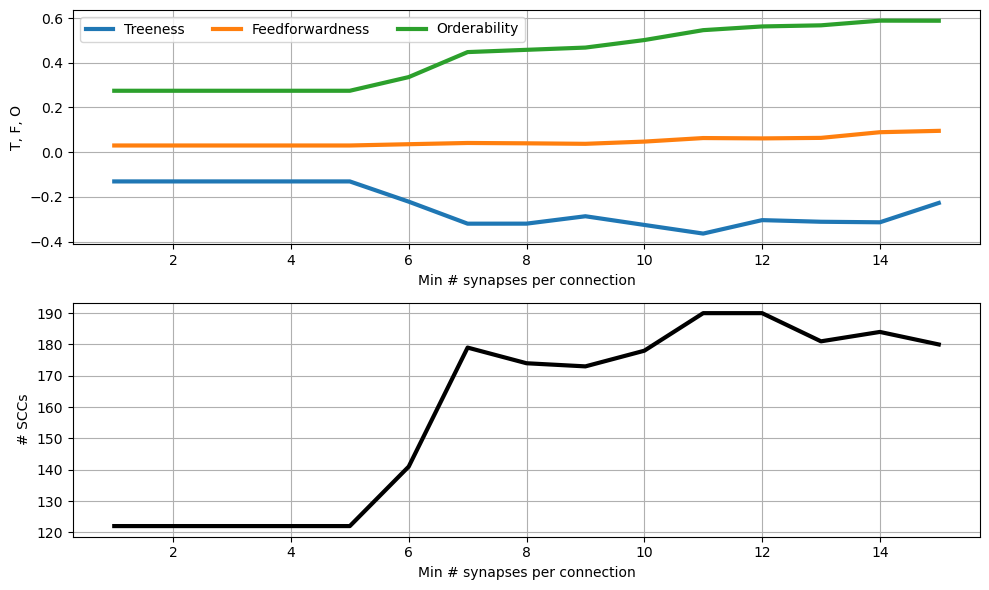

In [19]:
fig, axs = plt.subplots(2, 1, figsize=(10, 6), tight_layout=True)

axs[0].plot(df_tfo_aud['min_syn'], df_tfo_aud['treeness'], lw=3, label='Treeness')
axs[0].plot(df_tfo_aud['min_syn'], df_tfo_aud['feedforwardness'], lw=3, label='Feedforwardness')
axs[0].plot(df_tfo_aud['min_syn'], df_tfo_aud['orderability'], lw=3, label='Orderability')

axs[0].set_xlabel('Min # synapses per connection')
axs[0].set_ylabel('T, F, O')
axs[0].legend(ncol=3)
axs[0].grid(True)

axs[1].plot(df_tfo_aud['min_syn'], df_tfo_aud['num_scc'], lw=3, color='black')

axs[1].set_xlabel('Min # synapses per connection')
axs[1].set_ylabel('# SCCs')
axs[1].grid(True)


plt.show()

SCC sizes (min_syn = 10):
[np.int64(160), np.int64(4), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(

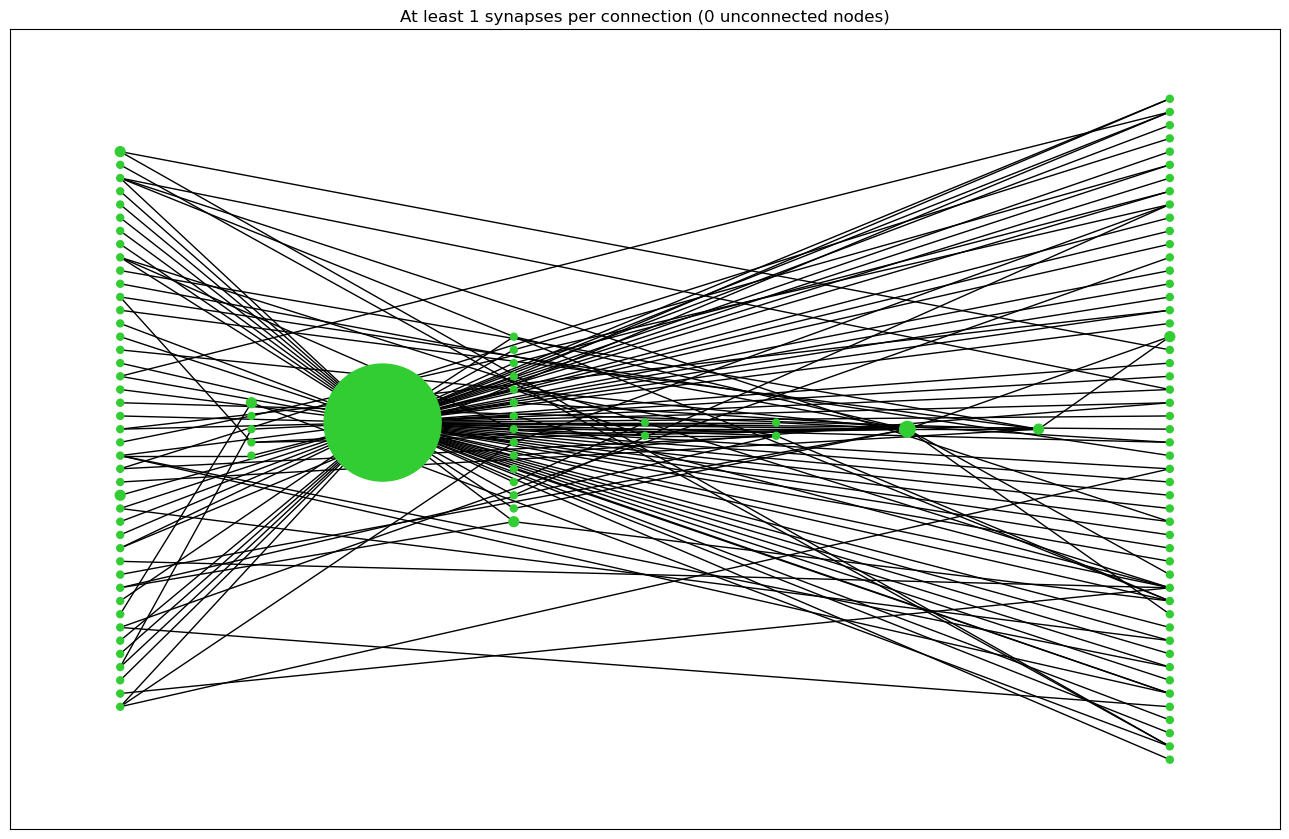

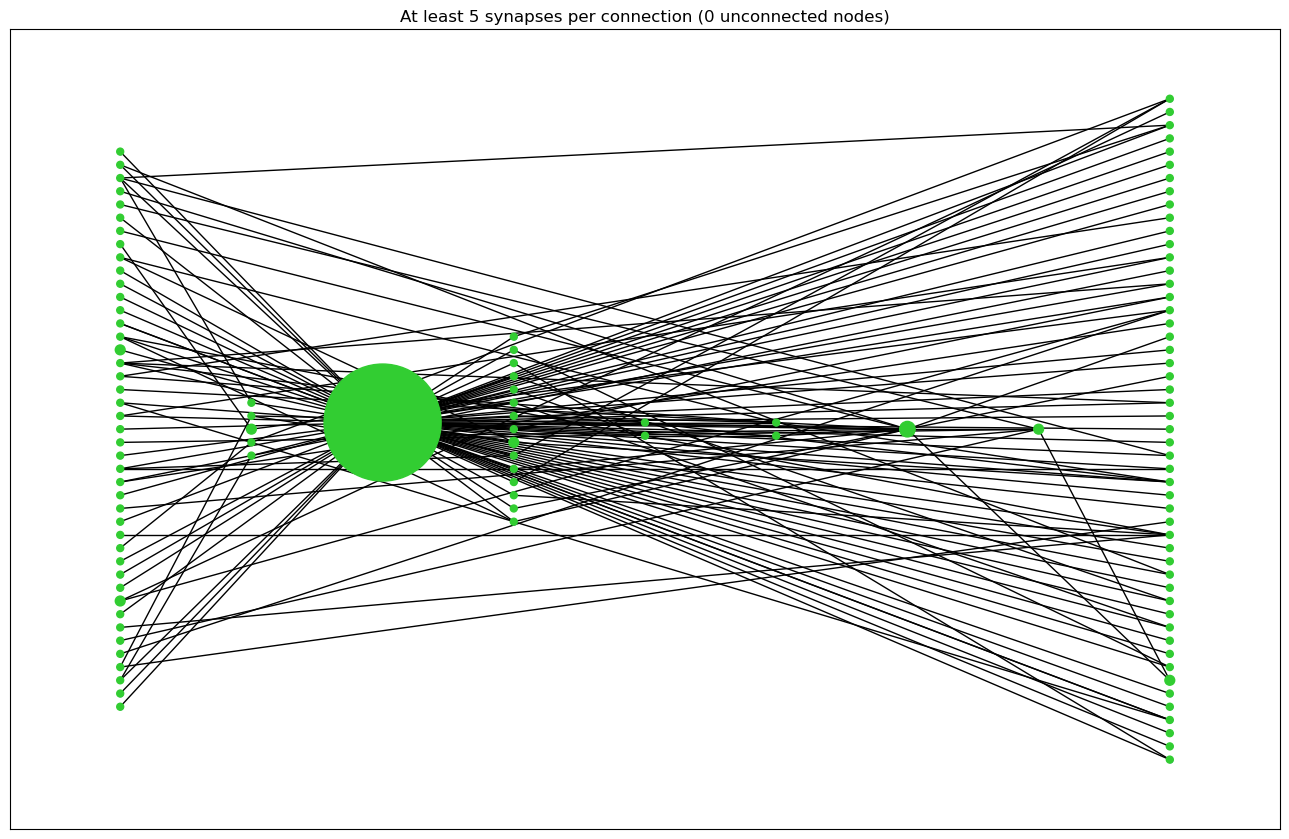

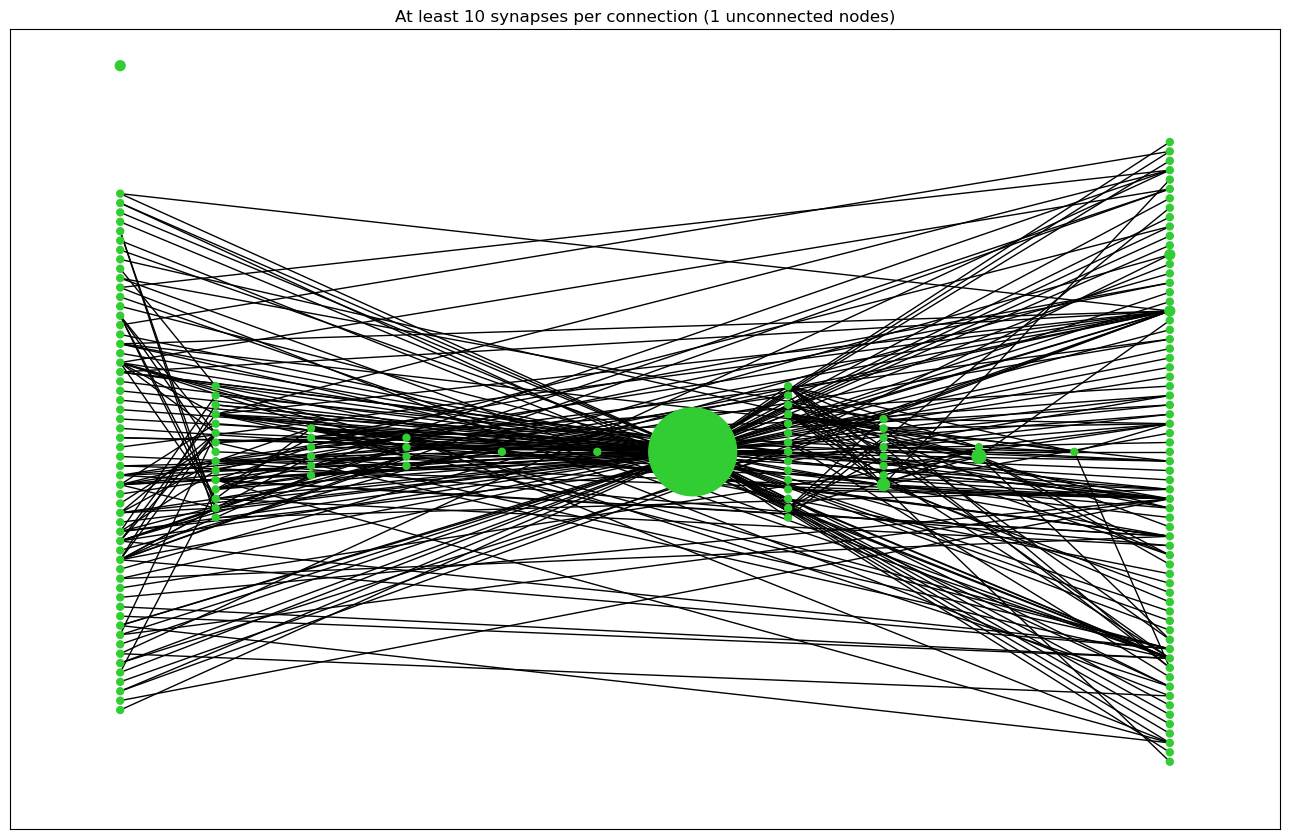

In [20]:
min_syns_rand = [1, 5, 10]

for cs, min_syn in enumerate(min_syns_rand):
    
    g_fly = nx.DiGraph()
    
    for i, row in conns_aud.iterrows():
        if row['syn_count'] >= min_syn:
            g_fly.add_node(row['pre_root_id'], label=['type_pre'])
            g_fly.add_node(row['post_root_id'], label=['type_post'])
            g_fly.add_edge(row['pre_root_id'], row['post_root_id'], weight=row['syn_count'])

    gc_fly, scc_fly = get_gc(g_fly)
    
    # get graphical attributes of nodes
    assert nx.is_directed_acyclic_graph(gc_fly)
    
    node_list = np.array(list(gc_fly.nodes()))
    
    k_ins = gc_fly.in_degree()
    k_outs = gc_fly.out_degree()
    
    max_nodes = np.array([v for v, k_in in k_ins if k_in == 0])
    
    xs = {v: 0 for v in max_nodes}
    member_dict = {v: gc_fly.nodes()[v]['members'] for v in gc_fly.nodes()}
    
    prev_nodes = max_nodes.copy()
    
    for i in range(100):
        # get all children of previous set of nodes
        child_list = sum([list(gc_fly.successors(v)) for v in prev_nodes], [])
        
        if not child_list:
            break
        next_nodes = np.array(list(set(child_list)))
        
        for v in next_nodes:
            xs[v] = i+1
            
        prev_nodes = next_nodes
    else:
        raise Exception('for loop reached 100 iters')
    
    for v in node_list:
        if k_ins[v] == k_outs[v] == 0:
            xs[v] = np.nan
            
    x_max = np.nanmax(list(xs.values()))
    for v in node_list:
        if k_outs[v] == 0 and k_ins[v] > 0:
            xs[v] = x_max
         
    # set y positions
    ys = {v: np.nan for v in node_list}
    for x_ in xs.values():
        nodes_this_x = [v for v in gc_fly.nodes() if xs[v] == x_]
        ys_ = np.random.permutation(len(nodes_this_x))
        for y_, v_ in zip(ys_, nodes_this_x):
            ys[v_] = y_ - len(nodes_this_x)/2
            
    pos = {v: (xs[v], ys[v]) for v in node_list}
    alphs = np.array([len(member_dict[v]) for v in node_list])
    
    unconnected = [v for v in node_list if np.isnan(pos[v][0])]
    n_unconnected = len(unconnected)
    
    xr = np.nanmax(list(xs.values())) - np.nanmin(list(xs.values()))
    x_unc = np.nanmin(list(xs.values())) + xr/50 * (np.arange(n_unconnected)%50)
    y_unc = np.nanmax(list(ys.values()))*(1.25 + .05*(np.arange(n_unconnected) // 50))
    
    for cv, v in enumerate(unconnected):
        pos[v] = (x_unc[cv], y_unc[cv])
    
    fig, ax = plt.subplots(1, 1, figsize=(13, 8.5), tight_layout=True)
    nx.drawing.draw_networkx(gc_fly, pos=pos, node_size=10, ax=ax, with_labels=False, arrows=False, arrowsize=10)
    ax.scatter(*zip(*[pos[v] for v in node_list]), s=25*alphs, zorder=1000, c='limegreen')
    ax.set_title(f'At least {min_syn} synapses per connection ({n_unconnected} unconnected nodes)')
        
print(f'SCC sizes (min_syn = {min_syn}):')
print(sorted(alphs)[::-1])
print(f'sum = {np.sum(alphs)}\n')

In [21]:
print(f'Largest SCC for min_syn = {min_syn}:')
print(list(scc_fly[np.argmax(alphs)]))

temp_true = []
temp_mostly_false = []

for u in np.random.choice(list(scc_fly[np.argmax(alphs)]), 50):
    for v in np.random.choice(list(scc_fly[np.argmax(alphs)]), 50):
        temp_true.append(nx.has_path(g_fly, u, v) and nx.has_path(g_fly, v, u))

for u in np.random.choice([i for i in range(493) if i not in scc_fly[np.argmax(alphs)]], 50):
    for v in np.random.choice([i for i in range(493) if i not in scc_fly[np.argmax(alphs)]], 50):
        temp_mostly_false.append(nx.has_path(g_fly, u, v) and nx.has_path(g_fly, v, u))
        
print(list(np.array(temp_true).astype(int)))
print(list(np.array(temp_mostly_false).astype(int)))

Largest SCC for min_syn = 10:
[720575940627410944, 720575940617197057, 720575940628910095, 720575940625032721, 720575940620392984, 720575940622529574, 720575940621043753, 720575940631153194, 720575940627350060, 720575940612523571, 720575940616611382, 720575940627235386, 720575940614840891, 720575940616121408, 720575940607188036, 720575940615723077, 720575940616211013, 720575940614450774, 720575940637410394, 720575940632715359, 720575940618758753, 720575940610638434, 720575940620980323, 720575940634606693, 720575940603186790, 720575940634126949, 720575940626228329, 720575940613943413, 720575940606743170, 720575940626042499, 720575940634126478, 720575940621146771, 720575940624134296, 720575940609673369, 720575940611674265, 720575940633044634, 720575940641545888, 720575940654117025, 720575940629954724, 720575940621242025, 720575940602914988, 720575940613311151, 720575940603683505, 720575940605308082, 720575940611335859, 720575940611864243, 720575940603636913, 720575940619034806, 720575940

NodeNotFound: Source 297 is not in G

**Next step: Null Model Comparison**